## HW6 APPM-5370
Jenn Kaphammer

In [18]:
import numpy as np
from scipy.optimize import brentq
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)

### Q1b - root-finding

In [4]:
#quotient
def f(T):
    return 0.5 * (1 - np.exp(-0.5 * T))

def g(T):
    return 1 - np.exp(-0.5 * T) + 0.5*T + 5

def f_prime(T):
    return 0.25 * np.exp(-0.5 * T)

def g_prime(T):
    return 0.5 * np.exp(-0.5 * T) + 0.5

def equation(T):
    return f_prime(T) * g(T) - f(T) * g_prime(T)

T_star = brentq(equation, 0, 20)

In [5]:
T_star = brentq(equation, 0, 20)
R_star = f(T_star) / g(T_star)

print("Optimal waiting time:", T_star)
print("Optimal intake rate:", R_star)

Optimal waiting time: 4.181434810310963
Optimal intake rate: 0.05500115972326258


### Q1c - Foraging simulations

In [11]:
#based on bandit.py from Canvas
import numpy as np

def run_foraging(T, n_visits=400_000, p_H=0.5, rho=0.5, tau=5, rng=None):
    #option to set seed
    rng = rng or np.random.default_rng()
    high = rng.random(n_visits) < p_H
    #exponential
    food_times = rng.exponential(scale=1/rho, size=n_visits)
    #if food was discovered before T
    found_food = high & (food_times <= T)
    search_time = np.where(
        high,
        np.minimum(food_times, T),
        T
    )
    # add travel time
    total_food = np.sum(found_food)
    total_time = np.sum(search_time) + n_visits * tau

    return total_food/total_time

def theoretical_rate(T, p_H=0.5, rho=0.5, tau=5):
    num = p_H * (1 - np.exp(-rho * T))
    denom = (
        (p_H / rho) * (1 - np.exp(-rho * T))
        + (1 - p_H) * T
        + tau
    )
    return num/denom

In [12]:
for T in [2, T_star, 10]:
    simulated = run_foraging(T, rng=rng)
    theoretical = theoretical_rate(T)

    print("T =", T)
    print("Simulated rate =", simulated)
    print("Theoretical rate =", theoretical)
    print()

T = 2
Simulated rate = 0.047715584626207966
Theoretical rate = 0.04765599126414329

T = 4.181434810310963
Simulated rate = 0.05501992419130348
Theoretical rate = 0.05500115972326258

T = 10
Simulated rate = 0.04532734553249578
Theoretical rate = 0.04517594723987209



The simulated results agree with the theoretical baseline. Out of the 3 $T$s, $T^*$ performed the best.

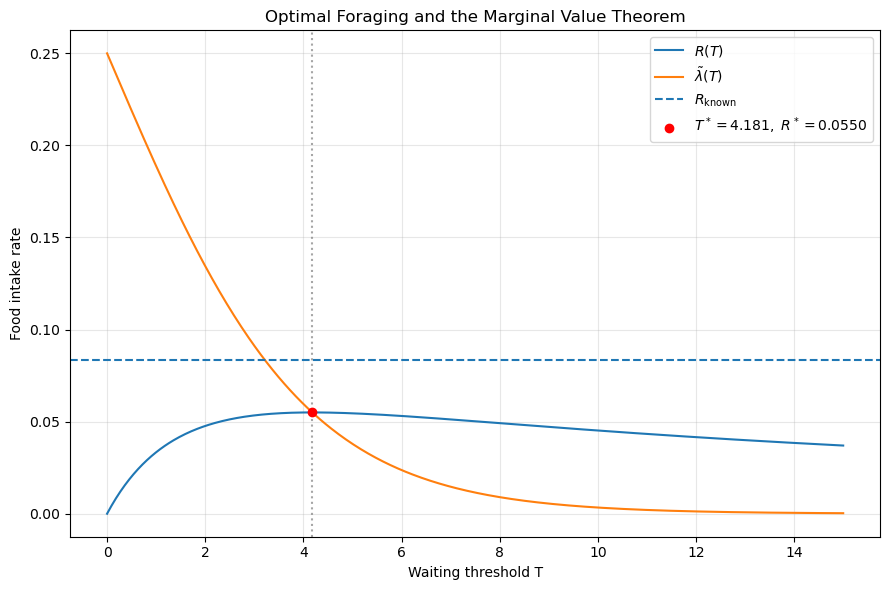

In [16]:
def lambda_tilde(T, p_H=0.5, rho=0.5):
    numerator = rho * p_H * np.exp(-rho * T)
    denominator = p_H * np.exp(-rho * T) + 1 - p_H
    return numerator / denominator

T_values = np.linspace(0, 15, 500)

R_values = theoretical_rate(T_values)
lambda_values = lambda_tilde(T_values)

R_star = theoretical_rate(T_star)
R_known = 0.5 / 6

plt.figure(figsize=(9, 6))

plt.plot(T_values, R_values, label=r"$R(T)$")
plt.plot(T_values, lambda_values, label=r"$\tilde{\lambda}(T)$")
plt.axhline(R_known, linestyle="--", label=r"$R_{\mathrm{known}}$")

# Mark the optimum
plt.scatter(T_star, R_star, color="red", zorder=5,
            label=rf"$T^*={T_star:.3f},\ R^*={R_star:.4f}$")

plt.axvline(T_star, color="gray", linestyle=":", alpha=0.7)

plt.xlabel("Waiting threshold T")
plt.ylabel("Food intake rate")
plt.title("Optimal Foraging and the Marginal Value Theorem")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Q2c - Game posession simulations

In [19]:
#define mean flow eq i)
eta = 0.02
x_star = 8/17
y_star = 9/17

def mean_flow(t, z):
    x, y = z
    dx = 0.85 * eta * (x * (1 - x))**2 * (y-y_star)
    dy = -0.85 * eta * (y * (1 - y))**2 * (x-x_star)
    return [dx, dy]

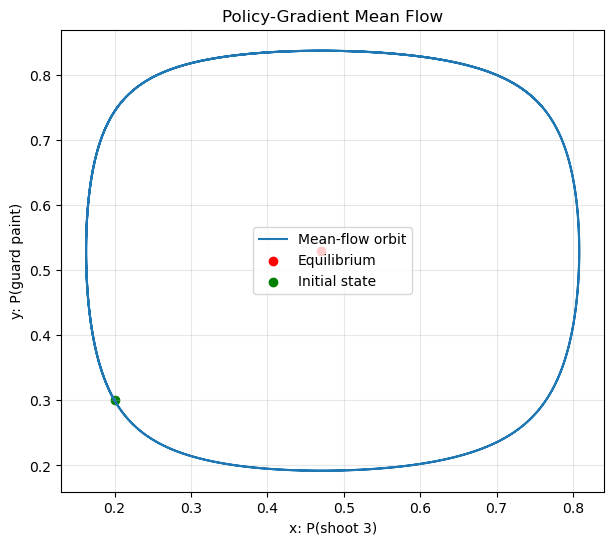

x range: 0.1627832098607998 0.8081856754149536
y range: 0.19181430972660463 0.8372167881558655


In [20]:
#integrate orbit
t_eval = np.linspace(0, 20000, 10000)

solution = solve_ivp(
    mean_flow,
    (0, 20000),
    [0.2, 0.3],
    t_eval=t_eval,
    rtol=1e-10,
    atol=1e-12
)

x = solution.y[0]
y = solution.y[1]

plt.figure(figsize=(7, 6))

plt.plot(x, y, label="Mean-flow orbit")
plt.scatter(x_star, y_star, color="red", label="Equilibrium")
plt.scatter(0.2, 0.3, color="green", label="Initial state")

plt.xlabel("x: P(shoot 3)")
plt.ylabel("y: P(guard paint)")
plt.title("Policy-Gradient Mean Flow")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("x range:", x.min(), x.max())
print("y range:", y.min(), y.max())

In [21]:
#variation of K
def F(s, c):
    return(c/s+(1-c)/(1-s)+(2*c-1)*np.log((1-s)/s))
def K(x, y):
    return (F(x, x_star)-F(x_star, x_star)+F(y, y_star) -F(y_star, y_star))

K_values = K(x, y)

print("Initial K:", K_values[0])
print("K variation:", np.ptp(K_values))

Initial K: 1.4338318234795
K variation: 4.544873810630179e-09


In [23]:
#ii)
def sigmoid(theta):
    return 1/(1+np.exp(-theta))

shot_probs = np.array([
    [0.40, 0.60], #s2
    [0.40, 0.25] #s3
])

In [28]:
def simulate_game(tau, n_possessions=400_000, seed=42):
    rng = np.random.default_rng(seed)
    theta1 = 0.3
    theta2 = -0.3
    #avg baseline for offensive points
    baseline = 0.0

    xs = np.zeros(n_possessions)
    ys = np.zeros(n_possessions)

    for t in range(n_possessions):
        x = sigmoid(theta1)
        y = sigmoid(theta2)
        xs[t] = x
        ys[t] = y

        # actions
        a1 = int(rng.random()<x)  # 1 = shoot 3
        a2 = int(rng.random()<y)  # 1 = guard paint
        defense_col = 0 if a2 == 1 else 1
        made = rng.random() < shot_probs[a1, defense_col]
        points = (2 + a1) * int(made)
        r1 = points
        r2 = -points
        #baseline from prev posessions
        b1 = baseline
        b2 = -baseline

        # Simultaneous policy-gradient updates
        theta1 += eta * (
            (r1 - b1) * (a1 - x)
            - tau * theta1 * x * (1 - x)
        )

        theta2 += eta * (
            (r2 - b2) * (a2 - y)
            - tau * theta2 * y * (1 - y)
        )

        #update baseline
        baseline += (points - baseline) / (t + 1)

    return xs, ys

In [29]:
x0, y0 = simulate_game(tau=0)
x1, y1 = simulate_game(tau=0.05)

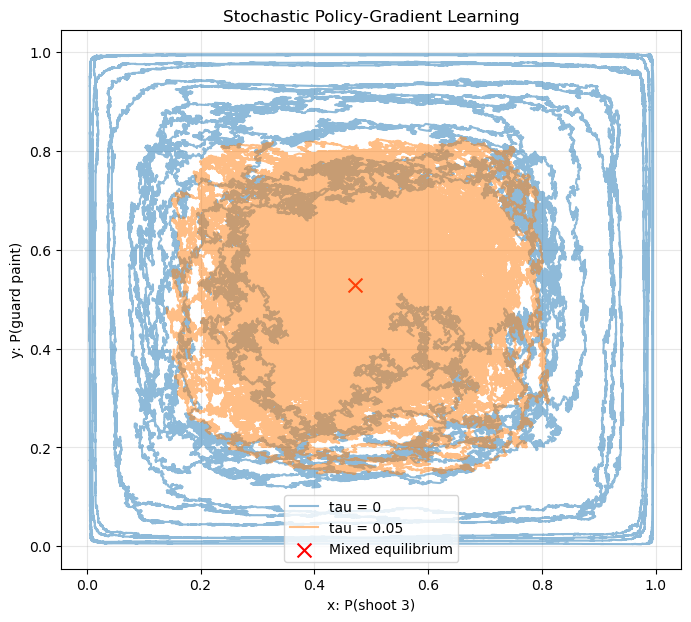

In [31]:
#plot trajectories
plt.figure(figsize=(8, 7))

plt.plot(x0, y0, alpha=0.5, label="tau = 0")
plt.plot(x1, y1, alpha=0.5, label="tau = 0.05")

plt.scatter(
    x_star, y_star,
    color="red",
    marker="x",
    s=100,
    label="Mixed equilibrium"
)

plt.xlabel("x: P(shoot 3)")
plt.ylabel("y: P(guard paint)")
plt.title("Stochastic Policy-Gradient Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [34]:
#last-quarter average and the mean distance from equilibrium
def report_statistics(xs, ys, label):
    n = len(xs)
    quarter = n // 4

    distances = np.sqrt(
        (xs - x_star)**2 + (ys - y_star)**2
    )

    print(label)
    print("Last-quarter average x:", np.mean(xs[-quarter:]))
    print("Last-quarter average y:", np.mean(ys[-quarter:]))
    print("Mean distance early:", np.mean(distances[:quarter]))
    print("Mean distance late:", np.mean(distances[-quarter:]))
    print()

report_statistics(x0, y0, "tau = 0")
report_statistics(x1, y1, "tau = 0.05")

tau = 0
Last-quarter average x: 0.518892215294167
Last-quarter average y: 0.4669979511268722
Mean distance early: 0.40409570296206054
Mean distance late: 0.6698151726398694

tau = 0.05
Last-quarter average x: 0.4544180034074595
Last-quarter average y: 0.5181840811495538
Mean distance early: 0.1916931518047751
Mean distance late: 0.1545521786450138

